In [38]:
!pip -q install factor-analyzer
!wget -O wine.csv https://raw.githubusercontent.com/Turbonik/Data-Analysis/main/wine.csv

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import shapiro

from sklearn.preprocessing import StandardScaler

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import (
    calculate_bartlett_sphericity,
    calculate_kmo
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)

RANDOM_STATE = 42

df = pd.read_csv('wine.csv')

df.head()

--2026-11-26 05:56:24--  https://raw.githubusercontent.com/Turbonik/Data-Analysis/main/wine.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10782 (11K) [text/plain]
Saving to: ‘wine.csv’

wine.csv            100%[===================>]  10.53K  --.-KB/s    in 0s      

2026-11-26 05:56:24 (76.6 MB/s) - ‘wine.csv’ saved [10782/10782]



,1,14.23,1.71,2.43,15.6,127,2.8,3.06,.28,2.29,5.64,1.04,3.92,1065
0,1,13.2000,1.7800,2.1400,11.2000,100,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050
1,1,13.1600,2.3600,2.6700,18.6000,101,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185
2,1,14.3700,1.9500,2.5000,16.8000,113,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480
3,1,13.2400,2.5900,2.8700,21.0000,118,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735
4,1,14.2000,1.7600,2.4500,15.2000,112,3.2700,3.3900,0.3400,1.9700,6.7500,1.0500,2.8500,1450


# Дискриптивный анализ

In [39]:
df = pd.read_csv(
    'wine.csv',
    header=None
)

columns = [
    'Cultivator',
    'Alcohol',
    'Malic_Acid',
    'Ash',
    'Alcalinity_of_Ash',
    'Magnesium',
    'Total_Phenols',
    'Flavanoids',
    'Nonflavanoid_Phenols',
    'Proanthocyanins',
    'Color_Intensity',
    'Hue',
    'OD280_OD315',
    'Proline'
]

df.columns = columns
X = df.drop(columns='Cultivator')
X.head()
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Alcalinity_of_Ash     178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280_OD315           178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [40]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)

descriptive_stats = pd.DataFrame({
    'mean': X.mean(),
    'median': X.median(),
    'std': X.std(),
    'min': X.min(),
    'q1': q1,
    'q3': q3,
    'iqr': q3 - q1,
    'max': X.max(),
    'skew': X.skew(),
    'kurtosis': X.kurtosis()
})

descriptive_stats.round(4)


,mean,median,std,min,q1,q3,iqr,max,skew,kurtosis
Alcohol,13.0006,13.0500,0.8118,11.0300,12.3625,13.6775,1.3150,14.8300,-0.0515,-0.8525
Malic_Acid,2.3363,1.8650,1.1171,0.7400,1.6025,3.0825,1.4800,5.8000,1.0397,0.2992
Ash,2.3665,2.3600,0.2743,1.3600,2.2100,2.5575,0.3475,3.2300,-0.1767,1.1440
Alcalinity_of_Ash,19.4949,19.5000,3.3396,10.6000,17.2000,21.5000,4.3000,30.0000,0.2130,0.4879
Magnesium,99.7416,98.0000,14.2825,70.0000,88.0000,107.0000,19.0000,162.0000,1.0982,2.1050
Total_Phenols,2.2951,2.3550,0.6259,0.9800,1.7425,2.8000,1.0575,3.8800,0.0866,-0.8356
Flavanoids,2.0293,2.1350,0.9989,0.3400,1.2050,2.8750,1.6700,5.0800,0.0253,-0.8804
Nonflavanoid_Phenols,0.3619,0.3400,0.1245,0.1300,0.2700,0.4375,0.1675,0.6600,0.4502,-0.6372
Proanthocyanins,1.5909,1.5550,0.5724,0.4100,1.2500,1.9500,0.7000,3.5800,0.5171,0.5546
Color_Intensity,5.0581,4.6900,2.3183,1.2800,3.2200,6.2000,2.9800,13.0000,0.8686,0.3815


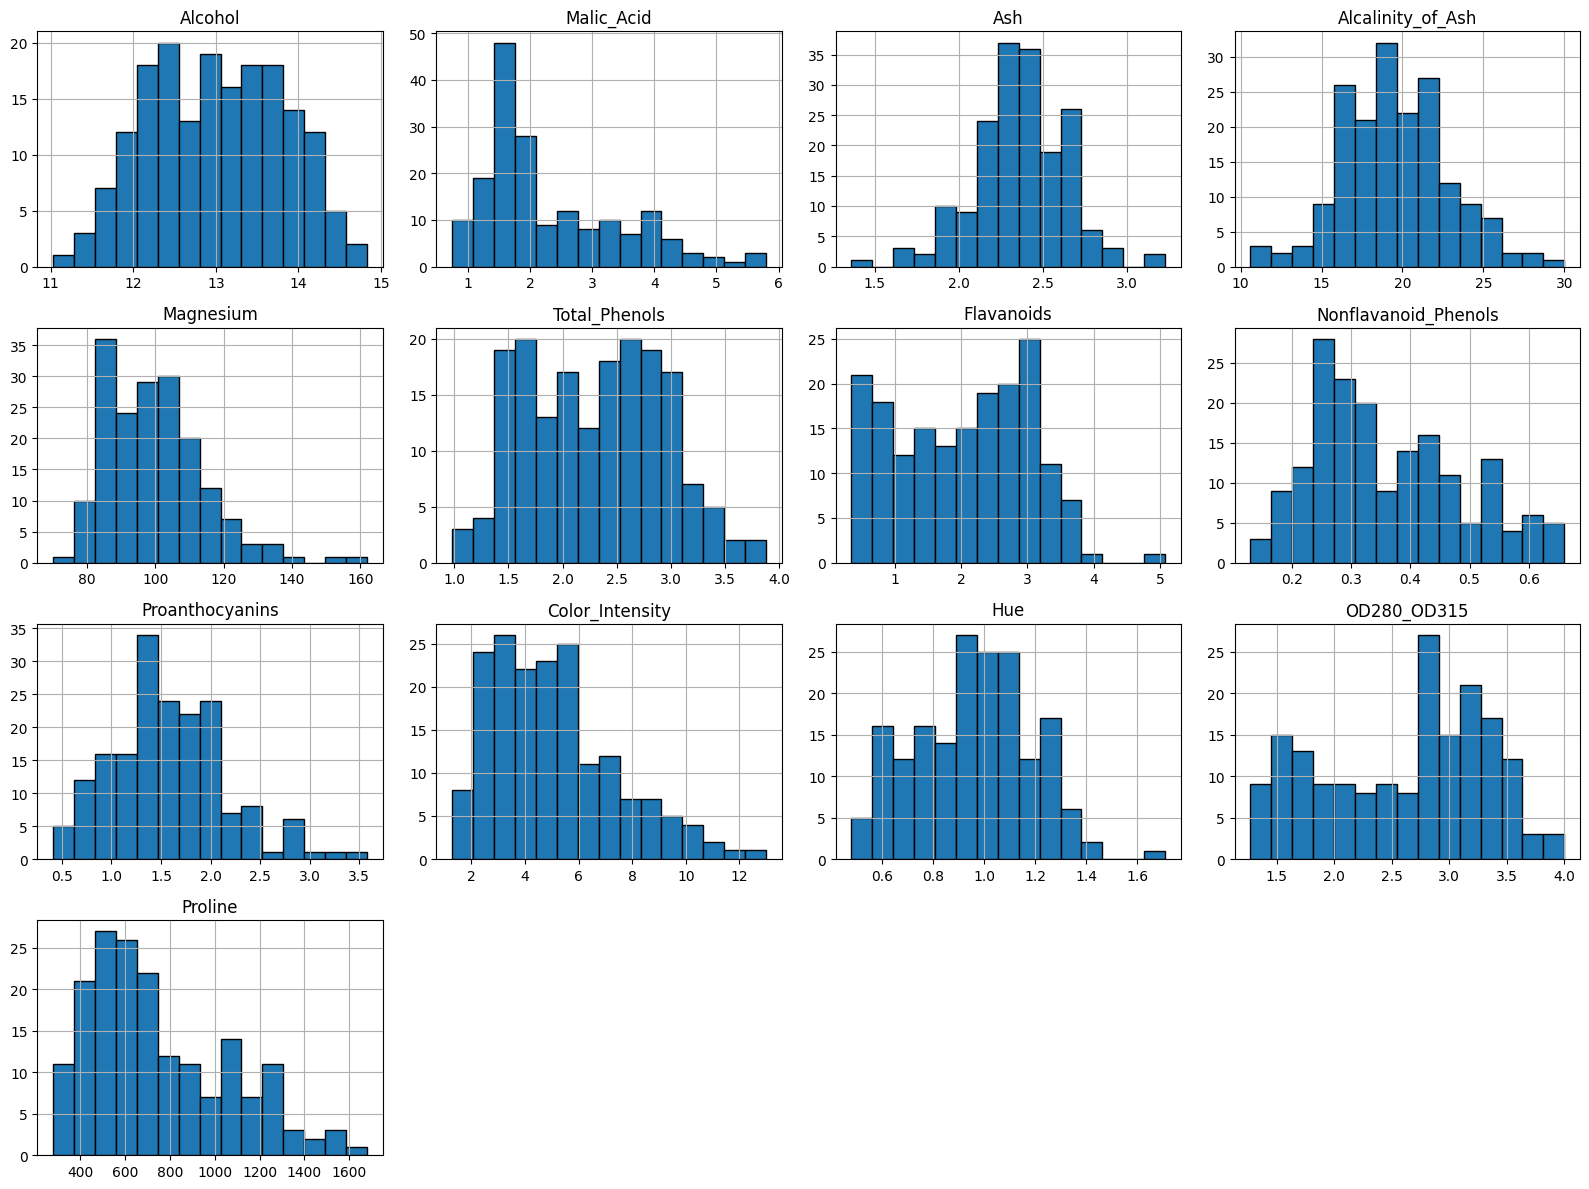

In [41]:
X.hist(
    bins=15,
    figsize=(16, 12),
    edgecolor='black'
)

plt.tight_layout()
plt.show()


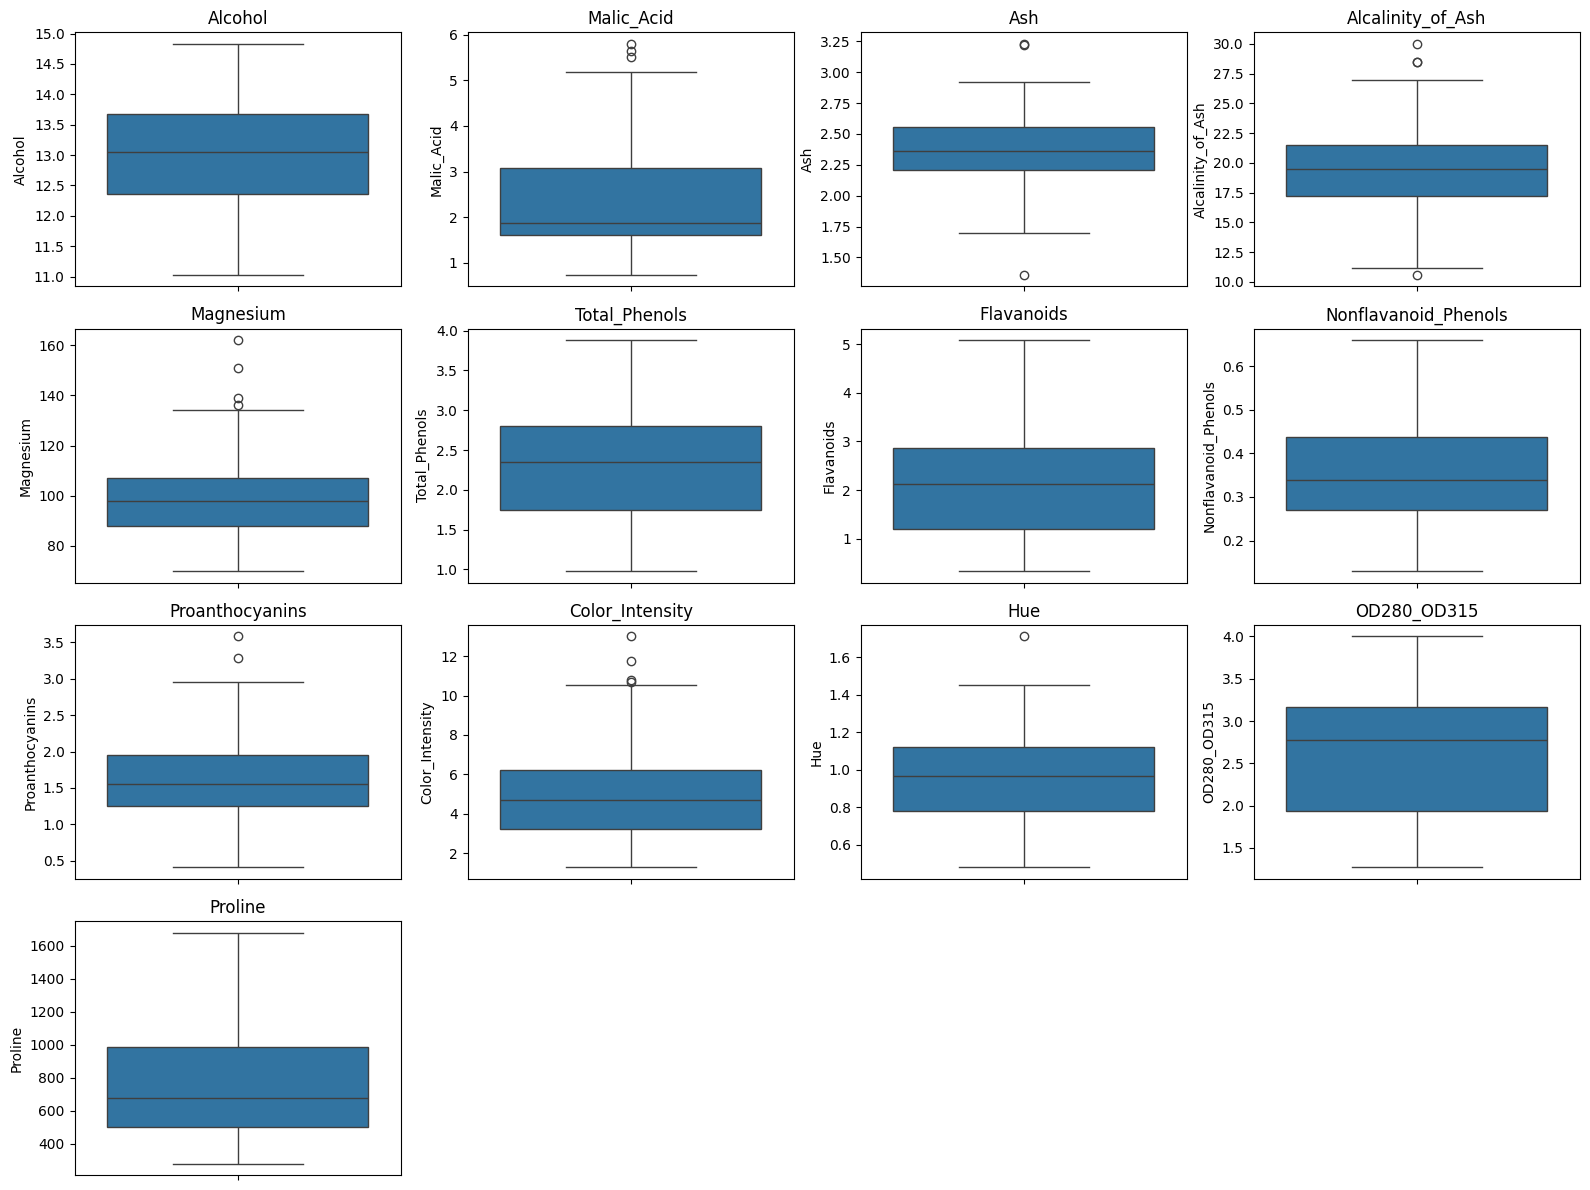

In [42]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

axes = axes.flatten()

for i, column in enumerate(X.columns):
    sns.boxplot(
        y=X[column],
        ax=axes[i]
    )

    axes[i].set_title(column)

for i in range(len(X.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Корреляционный анализ

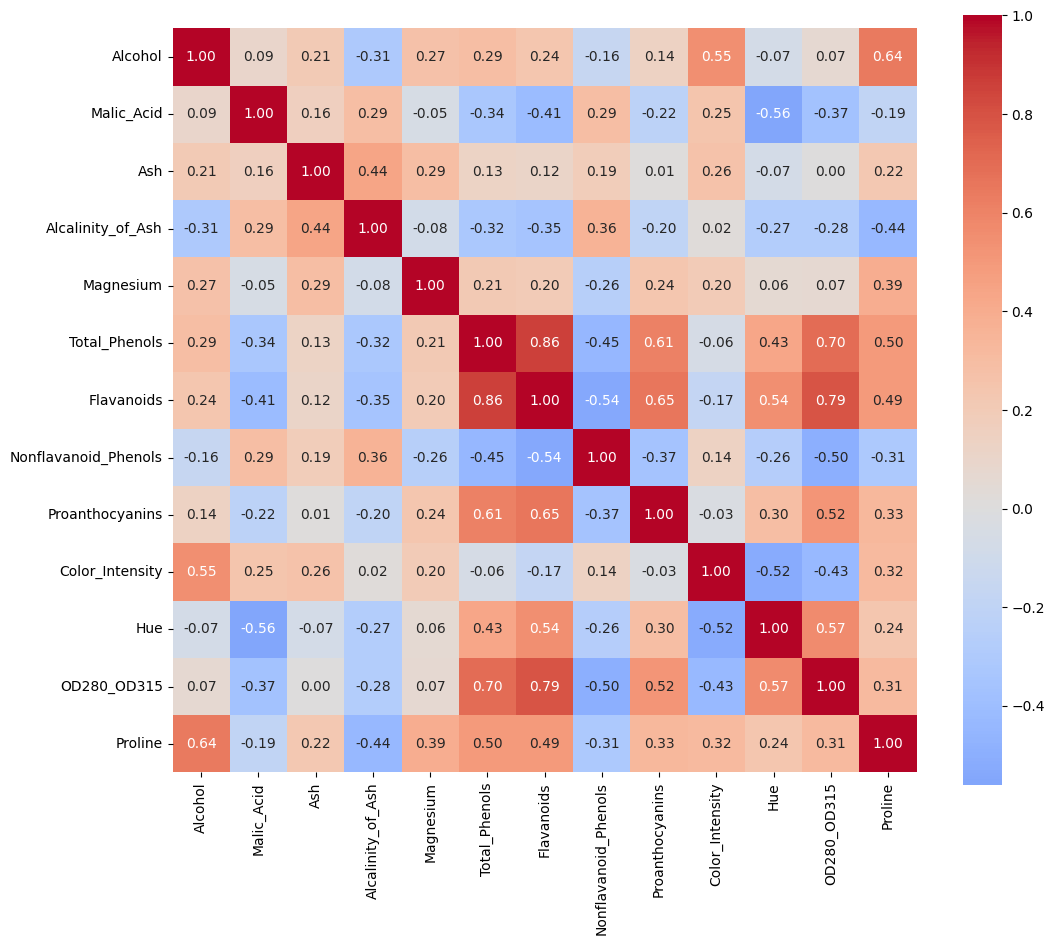

,,0
Total_Phenols,Flavanoids,0.8646
Flavanoids,OD280_OD315,0.7872
Total_Phenols,OD280_OD315,0.6999
Flavanoids,Proanthocyanins,0.6527
Alcohol,Proline,0.6437
Total_Phenols,Proanthocyanins,0.6124
Hue,OD280_OD315,0.5655
Malic_Acid,Hue,-0.5613
Alcohol,Color_Intensity,0.5464
Flavanoids,Hue,0.5435


In [43]:
corr_matrix = X.corr()

corr_matrix.round(3)
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True
)

plt.show()

corr_pairs = (
    corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

corr_pairs.head(15)

In [44]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

X_scaled.head()

,Alcohol,Malic_Acid,Ash,Alcalinity_of_Ash,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline
0,1.5186,-0.5622,0.2321,-1.1696,1.9139,0.8090,1.0348,-0.6596,1.2249,0.2517,0.3622,1.8479,1.0130
1,0.2463,-0.4994,-0.8280,-2.4908,0.0181,0.5686,0.7336,-0.8207,-0.5447,-0.2933,0.4061,1.1134,0.9652
2,0.1969,0.0212,1.1093,-0.2687,0.0884,0.8090,1.2155,-0.4984,2.1360,0.2690,0.3183,0.7886,1.3951
3,1.6915,-0.3468,0.4879,-0.8093,0.9309,2.4914,1.4665,-0.9819,1.0322,1.1861,-0.4275,1.1841,2.3346
4,0.2957,0.2277,1.8404,0.4519,1.2820,0.8090,0.6634,0.2268,0.4014,-0.3193,0.3622,0.4496,-0.0379


# Факторный анализ

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer import FactorAnalyzer

n_features = X_scaled.shape[1]

fa_initial = FactorAnalyzer(n_factors=n_features, rotation=None, method='principal')
fa_initial.fit(X_scaled)

eigenvalues, _ = fa_initial.get_eigenvalues()

eigen_df = pd.DataFrame({
    'Компонента': range(1, len(eigenvalues) + 1),
    'Собственное число': eigenvalues,
    'Доля дисперсии (%)': (eigenvalues / n_features) * 100,
    'Накопленная доля дисперсии (%)': np.cumsum(eigenvalues) / n_features * 100
})

print("Таблица собственных чисел:")
print(eigen_df.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Таблица собственных чисел:
    Компонента  Собственное число  Доля дисперсии (%)  Накопленная доля дисперсии (%)
0            1             4.7060             36.1990                         36.1990
1            2             2.4970             19.2070                         55.4060
2            3             1.4460             11.1240                         66.5300
3            4             0.9190              7.0690                         73.5990
4            5             0.8530              6.5630                         80.1620
5            6             0.6420              4.9360                         85.0980
6            7             0.5510              4.2390                         89.3370
7            8             0.3480              2.6810                         92.0180
8            9             0.2890              2.2220                         94.2400
9           10             0.2510              1.9300                         96.1700
10          11             

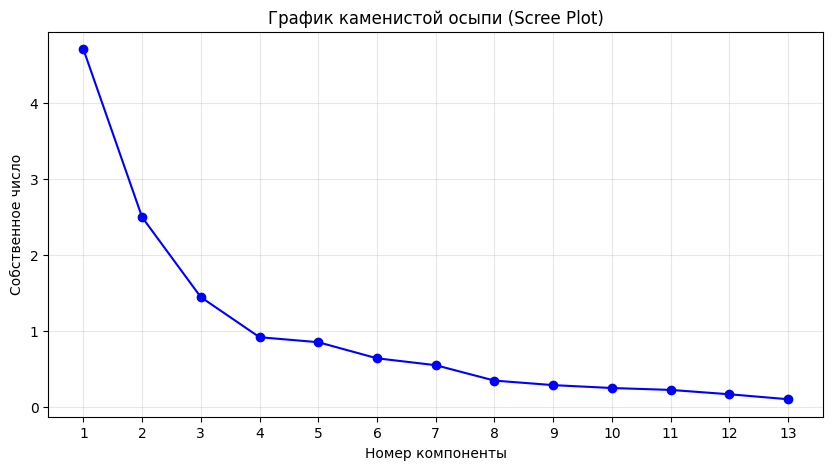

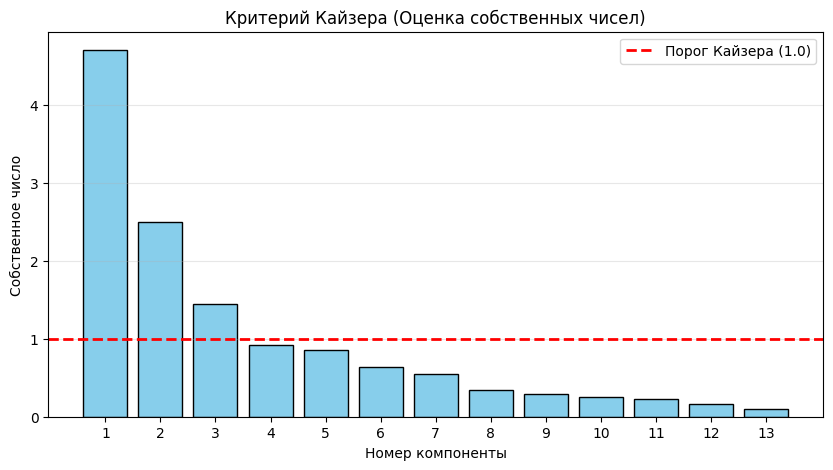

In [48]:
ы

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Матрица факторных нагрузок ДО вращения:
                      Фактор 1  Фактор 2  Фактор 3
Alcohol                 0.3130    0.7640   -0.2490
Malic_Acid             -0.5320    0.3550    0.1070
Ash                    -0.0040    0.4990    0.7530
Alcalinity_of_Ash      -0.5190   -0.0170    0.7360
Magnesium               0.3080    0.4730    0.1570
Total_Phenols           0.8560    0.1030    0.1760
Flavanoids              0.9170   -0.0050    0.1810
Nonflavanoid_Phenols   -0.6480    0.0450    0.2050
Proanthocyanins         0.6800    0.0620    0.1800
Color_Intensity        -0.1920    0.8370   -0.1650
Hue                     0.6440   -0.4410    0.1020
OD280_OD315             0.8160   -0.2600    0.2000
Proline                 0.6220    0.5770   -0.1520

Матрица факторных нагрузок ПОСЛЕ вращения (Varimax):
                      Фактор 1  Фактор 2  Фактор 3
Alcohol                 0.0310    0.8570   -0.0970
Malic_Acid             -0.5590    0.1450    0.2950
Ash                     0.0610    0.318

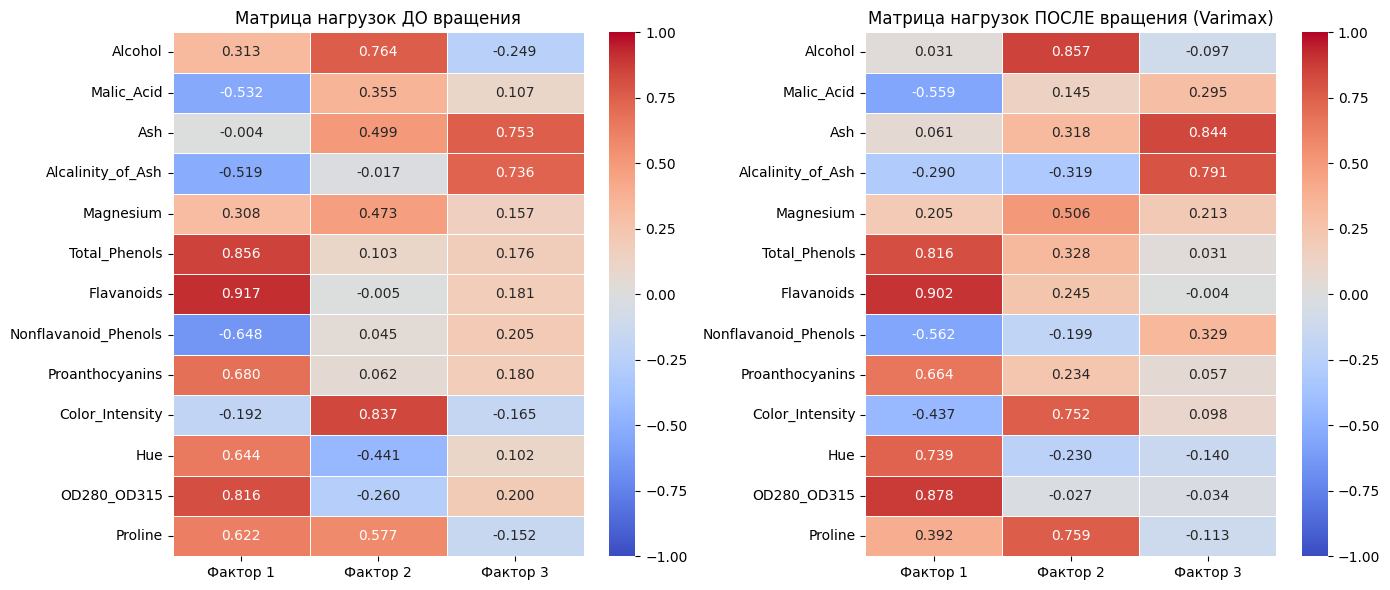

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer import FactorAnalyzer

n_factors = 3

fa_before = FactorAnalyzer(n_factors=n_factors, rotation=None, method='principal')
fa_before.fit(X_scaled)
loadings_before = pd.DataFrame(fa_before.loadings_, index=X_scaled.columns, columns=[f'Фактор {i+1}' for i in range(n_factors)])

fa_rotated = FactorAnalyzer(n_factors=n_factors, rotation='varimax', method='principal')
fa_rotated.fit(X_scaled)
loadings_rotated = pd.DataFrame(fa_rotated.loadings_, index=X_scaled.columns, columns=[f'Фактор {i+1}' for i in range(n_factors)])

print("Матрица факторных нагрузок ДО вращения:")
print(loadings_before.round(3))
print("\nМатрица факторных нагрузок ПОСЛЕ вращения (Varimax):")
print(loadings_rotated.round(3))

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.heatmap(loadings_before, annot=True, cmap='coolwarm', center=0, fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Матрица нагрузок ДО вращения')

plt.subplot(1, 2, 2)
sns.heatmap(loadings_rotated, annot=True, cmap='coolwarm', center=0, fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Матрица нагрузок ПОСЛЕ вращения (Varimax)')

plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


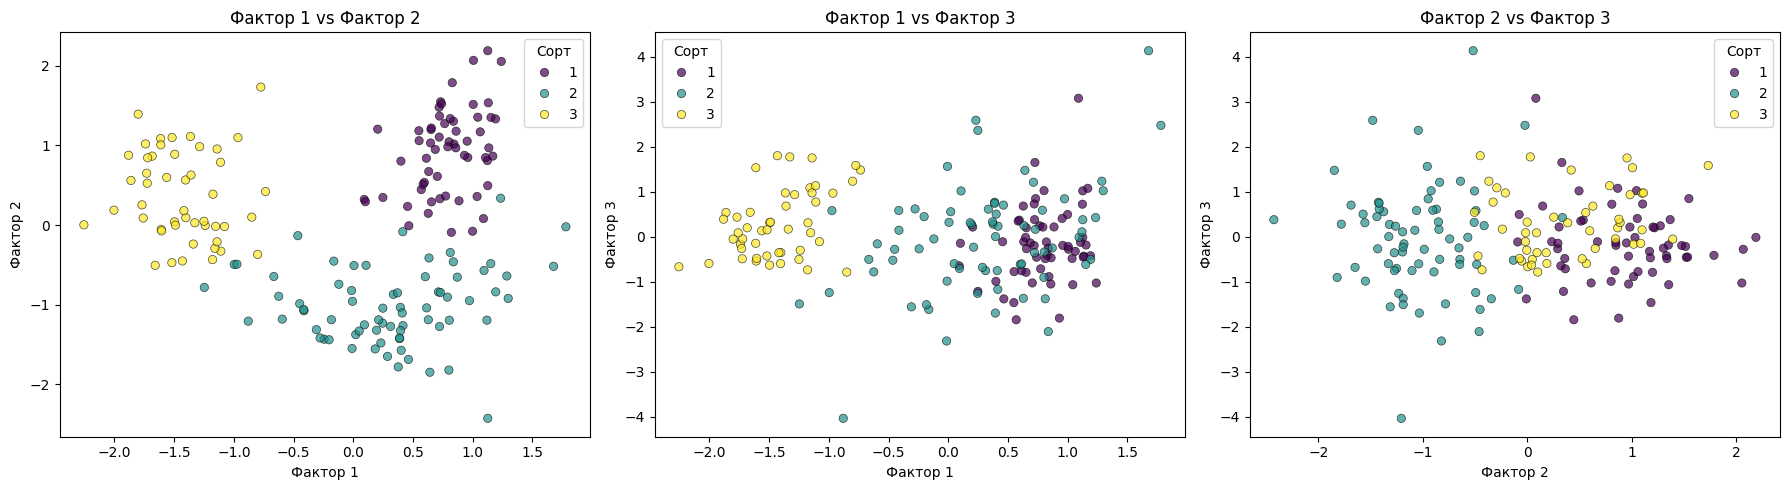

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

factor_scores = fa_rotated.transform(X_scaled)
factor_scores_df = pd.DataFrame(factor_scores, columns=[f'Фактор {i+1}' for i in range(n_factors)])
factor_scores_df['Cultivator'] = df['Cultivator'].values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=factor_scores_df, x='Фактор 1', y='Фактор 2', hue='Cultivator', palette='viridis', ax=axes[0], alpha=0.7, edgecolor='k', linewidth=0.5)
axes[0].set_title('Фактор 1 vs Фактор 2')
axes[0].legend(title='Сорт')

sns.scatterplot(data=factor_scores_df, x='Фактор 1', y='Фактор 3', hue='Cultivator', palette='viridis', ax=axes[1], alpha=0.7, edgecolor='k', linewidth=0.5)
axes[1].set_title('Фактор 1 vs Фактор 3')
axes[1].legend(title='Сорт')

sns.scatterplot(data=factor_scores_df, x='Фактор 2', y='Фактор 3', hue='Cultivator', palette='viridis', ax=axes[2], alpha=0.7, edgecolor='k', linewidth=0.5)
axes[2].set_title('Фактор 2 vs Фактор 3')
axes[2].legend(title='Сорт')

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/tmp/ipykernel_1519/2020054663.py:32: RuntimeWarning: invalid value encountered in log
  chi_square_lowley = -(n - 1 - (2*p + 5)/6 - (2*n_factors)/3) * np.log(det_R / det_R_plus)


1. КРИТЕРИЙ БАРТЛЕТТА (сферичность)
Хи-квадрат: 1317.181
p-value: 2.469e-224
Вывод: Модель адекватна (p < 0.05)

2. КРИТЕРИЙ КМО (Kaiser-Meyer-Olkin)
Общий KMO: 0.779

KMO для каждой переменной:
  Alcohol: 0.728
  Malic_Acid: 0.799
  Ash: 0.436
  Alcalinity_of_Ash: 0.683
  Magnesium: 0.683
  Total_Phenols: 0.873
  Flavanoids: 0.814
  Nonflavanoid_Phenols: 0.825
  Proanthocyanins: 0.855
  Color_Intensity: 0.617
  Hue: 0.788
  OD280_OD315: 0.868
  Proline: 0.819

3. КРИТЕРИЙ ЛОУЛИ-БАРТЛЕТТА (хи-квадрат для R+)
Хи-квадрат: nan
Степени свободы: 42.0
p-value: nan
Вывод: Нужно больше факторов (p < 0.05)

4. ТАБЛИЦА ОБЩНОСТЕЙ (Communalities)
          Переменная  Общность
             Alcohol    0.7440
          Malic_Acid    0.4210
                 Ash    0.8170
   Alcalinity_of_Ash    0.8120
           Magnesium    0.3440
       Total_Phenols    0.7740
          Flavanoids    0.8750
Nonflavanoid_Phenols    0.4630
     Proanthocyanins    0.4980
     Color_Intensity    0.7660
                

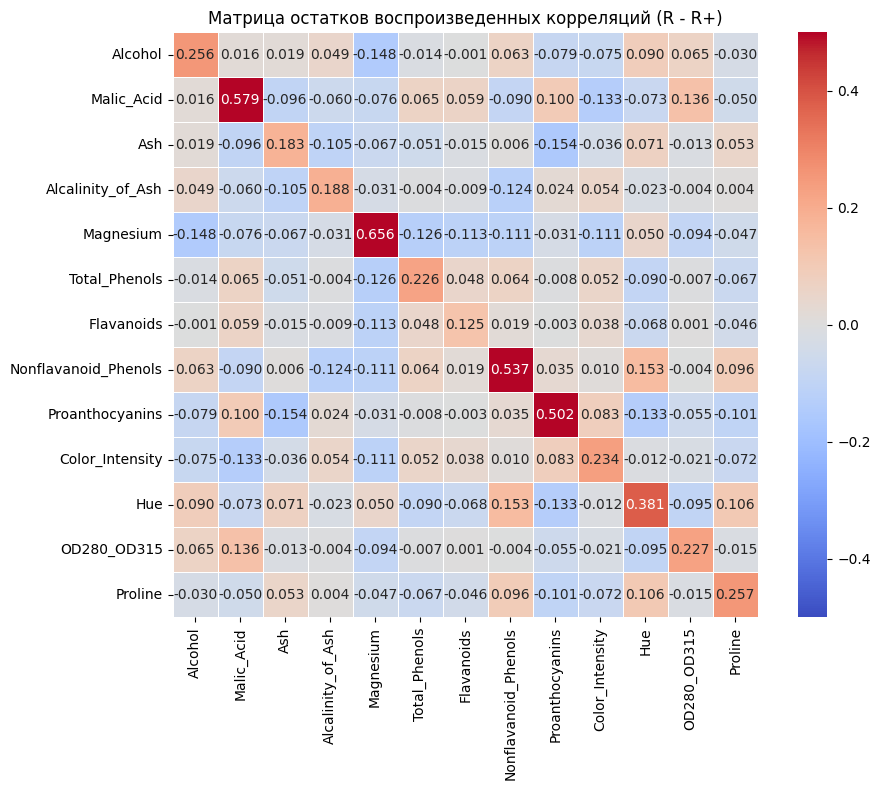

In [57]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

n_factors = 3
n = X_scaled.shape[0]
p = X_scaled.shape[1]

fa_rotated = FactorAnalyzer(n_factors=n_factors, rotation='varimax', method='principal')
fa_rotated.fit(X_scaled)

chi_square_bartlett, p_value_bartlett = calculate_bartlett_sphericity(X_scaled)
kmo_all, kmo_model = calculate_kmo(X_scaled)

communalities = fa_rotated.get_communalities()
communalities_df = pd.DataFrame({
    'Переменная': X_scaled.columns,
    'Общность': communalities
})

loadings = fa_rotated.loadings_
reproduced_corr = loadings @ loadings.T
original_corr = X_scaled.corr().values
residual_corr = original_corr - reproduced_corr

det_R = np.linalg.det(original_corr)
det_R_plus = np.linalg.det(reproduced_corr)

chi_square_lowley = -(n - 1 - (2*p + 5)/6 - (2*n_factors)/3) * np.log(det_R / det_R_plus)
df_lowley = ((p - n_factors)**2 - p - n_factors) / 2
p_value_lowley = 1 - stats.chi2.cdf(chi_square_lowley, df_lowley)

print("=" * 60)
print("1. КРИТЕРИЙ БАРТЛЕТТА (сферичность)")
print("=" * 60)
print(f"Хи-квадрат: {chi_square_bartlett:.3f}")
print(f"p-value: {p_value_bartlett:.3e}")
print(f"Вывод: {'Модель адекватна (p < 0.05)' if p_value_bartlett < 0.05 else 'Модель неадекватна'}")

print("\n" + "=" * 60)
print("2. КРИТЕРИЙ КМО (Kaiser-Meyer-Olkin)")
print("=" * 60)
print(f"Общий KMO: {kmo_model:.3f}")
print("\nKMO для каждой переменной:")
for i, var in enumerate(X_scaled.columns):
    print(f"  {var}: {kmo_all[i]:.3f}")

print("\n" + "=" * 60)
print("3. КРИТЕРИЙ ЛОУЛИ-БАРТЛЕТТА (хи-квадрат для R+)")
print("=" * 60)
print(f"Хи-квадрат: {chi_square_lowley:.3f}")
print(f"Степени свободы: {df_lowley:.1f}")
print(f"p-value: {p_value_lowley:.3e}")
print(f"Вывод: {'Факторов достаточно (p > 0.05)' if p_value_lowley > 0.05 else 'Нужно больше факторов (p < 0.05)'}")

print("\n" + "=" * 60)
print("4. ТАБЛИЦА ОБЩНОСТЕЙ (Communalities)")
print("=" * 60)
print(communalities_df.round(3).to_string(index=False))
print(f"\nСредняя общность: {communalities.mean():.3f}")
print(f"Полнота факторизации: {communalities.sum() / p:.3f}")

print("\n" + "=" * 60)
print("5. МАТРИЦА ОСТАТКОВ ВОСПРОИЗВЕДЕННЫХ КОРРЕЛЯЦИЙ")
print("=" * 60)
residual_abs = np.abs(residual_corr)
np.fill_diagonal(residual_abs, 0)
large_residuals = np.sum(residual_abs > 0.05)
total_elements = residual_abs.size - p
percent_large = (large_residuals / total_elements) * 100
print(f"Остатков с |значение| > 0.05: {large_residuals} из {total_elements} ({percent_large:.1f}%)")

plt.figure(figsize=(10, 8))
sns.heatmap(residual_corr, annot=True, cmap='coolwarm', center=0, fmt='.3f',
            linewidths=0.5, vmin=-0.5, vmax=0.5, square=True,
            xticklabels=X_scaled.columns, yticklabels=X_scaled.columns)
plt.title('Матрица остатков воспроизведенных корреляций (R - R+)')
plt.tight_layout()
plt.show()